In [ ]:
import os
import kagglehub
import pandas as pd

# 1. Fetch the dataset directory path
dataset_dir = kagglehub.dataset_download("shashanknecrothapa/ames-housing-dataset")

# 2. Join the directory path with the exact CSV filename
csv_path = os.path.join(dataset_dir, "AmesHousing.csv")

ames_df = pd.read_csv(csv_path)

In [10]:
ames_df.info()
ames_df.iloc[0]

<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17  House Style      2930 non

Order                     1
PID               526301100
MS SubClass              20
MS Zoning                RL
Lot Frontage          141.0
                    ...    
Mo Sold                   5
Yr Sold                2010
Sale Type               WD 
Sale Condition       Normal
SalePrice            215000
Name: 0, Length: 82, dtype: object

In [20]:
feature_cols = ['Gr Liv Area', 'Total Bsmt SF', '1st Flr SF', '2nd Flr SF', 'Garage Area',
                'Overall Qual', 'Overall Cond', 'Kitchen Qual', 'Neighborhood', 'Year Built',
                'Year Remod/Add', 'Yr Sold']

X = ames_df[feature_cols]
y = ames_df['SalePrice']
combinedXy = pd.concat([X,y], axis=1)

print(X.describe())
print(y.describe())

unique_neighborhoods = X['Neighborhood'].unique()
print(unique_neighborhoods)

       Gr Liv Area  Total Bsmt SF   1st Flr SF   2nd Flr SF  Garage Area  \
count  2930.000000    2929.000000  2930.000000  2930.000000  2929.000000   
mean   1499.690444    1051.614544  1159.557679   335.455973   472.819734   
std     505.508887     440.615067   391.890885   428.395715   215.046549   
min     334.000000       0.000000   334.000000     0.000000     0.000000   
25%    1126.000000     793.000000   876.250000     0.000000   320.000000   
50%    1442.000000     990.000000  1084.000000     0.000000   480.000000   
75%    1742.750000    1302.000000  1384.000000   703.750000   576.000000   
max    5642.000000    6110.000000  5095.000000  2065.000000  1488.000000   

       Overall Qual  Overall Cond   Year Built  Year Remod/Add      Yr Sold  
count   2930.000000   2930.000000  2930.000000     2930.000000  2930.000000  
mean       6.094881      5.563140  1971.356314     1984.266553  2007.790444  
std        1.411026      1.111537    30.245361       20.860286     1.316613  
min

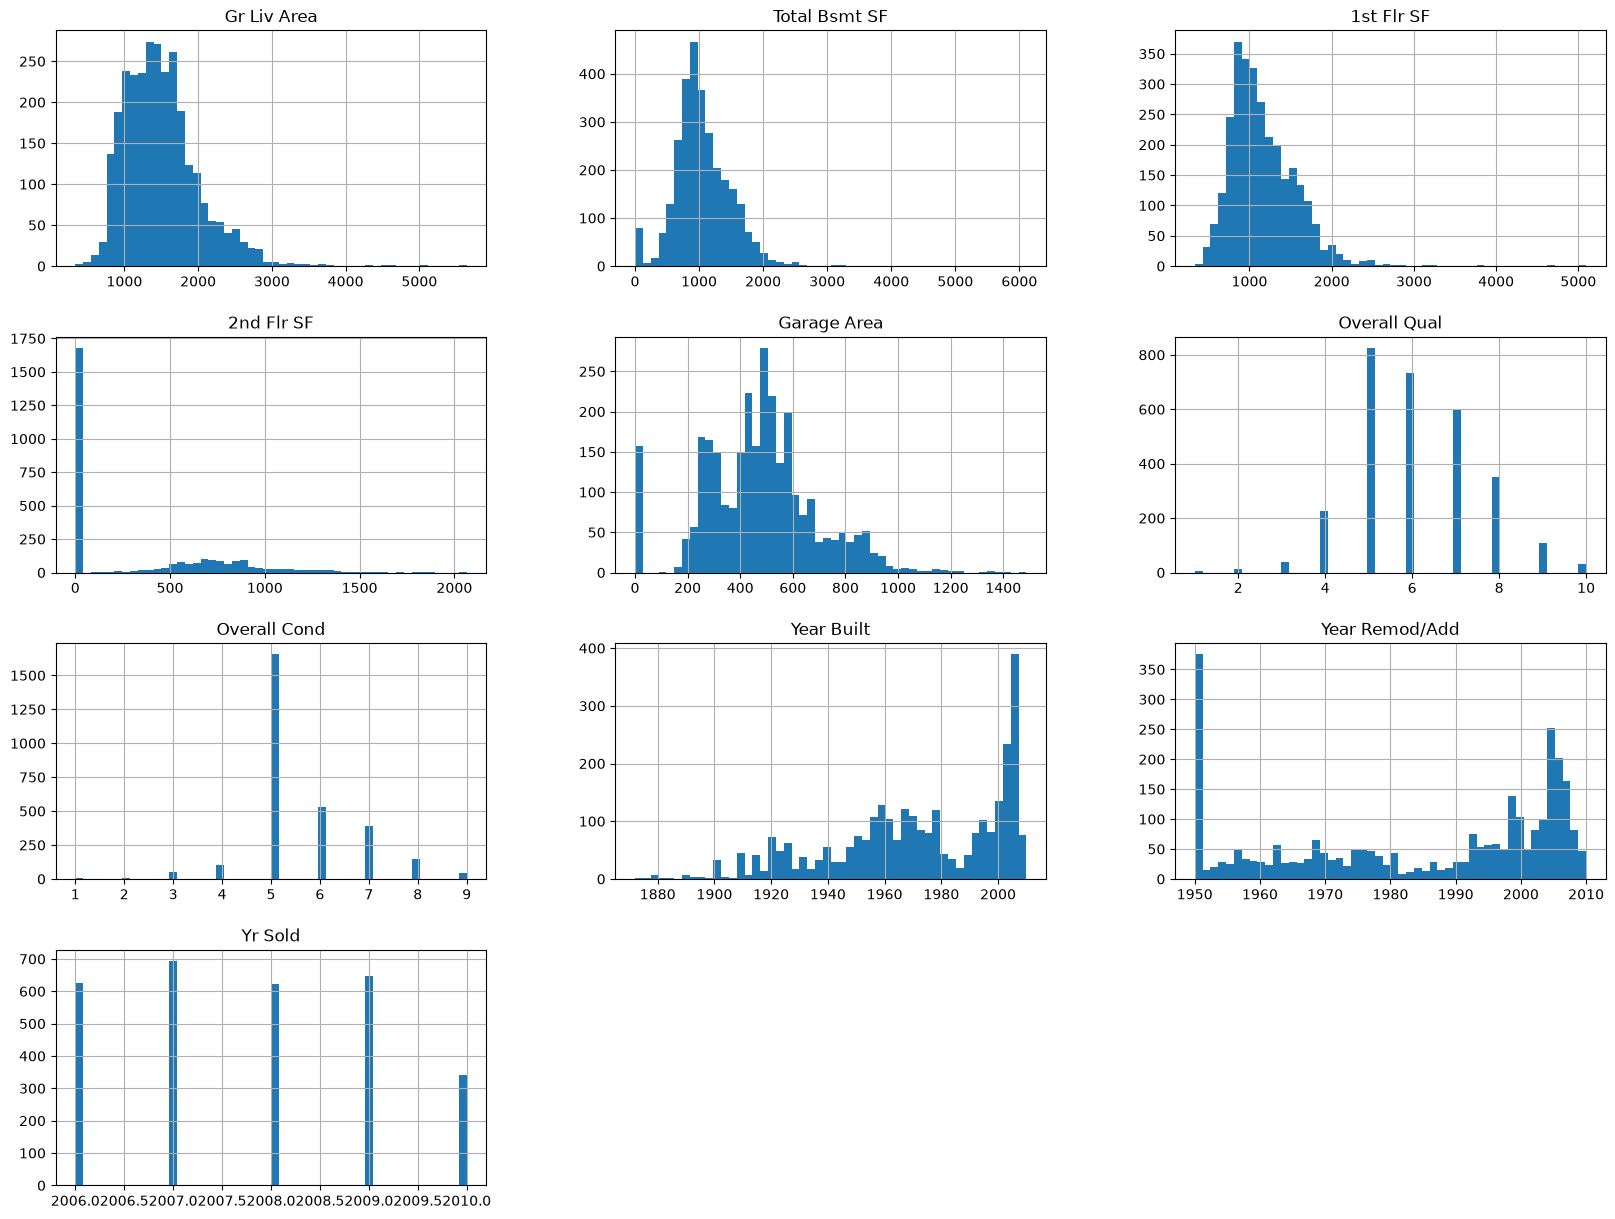

In [19]:
import matplotlib.pyplot as plt

X.hist(bins=50, figsize=(20,15))
plt.show()

In [21]:
corr_matrix = combinedXy.corr(numeric_only=True)
corr_matrix['SalePrice'].sort_values(ascending=False)

SalePrice         1.000000
Overall Qual      0.799262
Gr Liv Area       0.706780
Garage Area       0.640401
Total Bsmt SF     0.632280
1st Flr SF        0.621676
Year Built        0.558426
Year Remod/Add    0.532974
2nd Flr SF        0.269373
Yr Sold          -0.030569
Overall Cond     -0.101697
Name: SalePrice, dtype: float64

array([[<Axes: xlabel='SalePrice', ylabel='SalePrice'>,
        <Axes: xlabel='Overall Qual', ylabel='SalePrice'>,
        <Axes: xlabel='Gr Liv Area', ylabel='SalePrice'>,
        <Axes: xlabel='Garage Area', ylabel='SalePrice'>,
        <Axes: xlabel='Year Built', ylabel='SalePrice'>],
       [<Axes: xlabel='SalePrice', ylabel='Overall Qual'>,
        <Axes: xlabel='Overall Qual', ylabel='Overall Qual'>,
        <Axes: xlabel='Gr Liv Area', ylabel='Overall Qual'>,
        <Axes: xlabel='Garage Area', ylabel='Overall Qual'>,
        <Axes: xlabel='Year Built', ylabel='Overall Qual'>],
       [<Axes: xlabel='SalePrice', ylabel='Gr Liv Area'>,
        <Axes: xlabel='Overall Qual', ylabel='Gr Liv Area'>,
        <Axes: xlabel='Gr Liv Area', ylabel='Gr Liv Area'>,
        <Axes: xlabel='Garage Area', ylabel='Gr Liv Area'>,
        <Axes: xlabel='Year Built', ylabel='Gr Liv Area'>],
       [<Axes: xlabel='SalePrice', ylabel='Garage Area'>,
        <Axes: xlabel='Overall Qual', ylabel='Gara

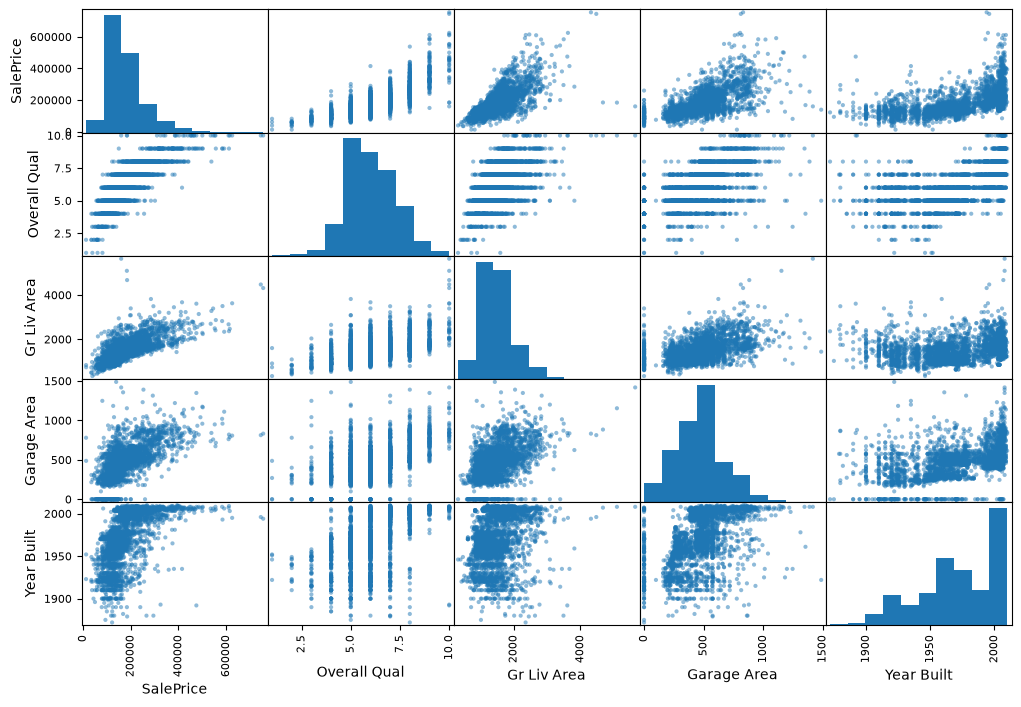

In [22]:
from pandas.plotting import scatter_matrix
attributes = ['SalePrice', 'Overall Qual', 'Gr Liv Area', 'Garage Area','Year Built']
scatter_matrix(combinedXy[attributes], figsize=(12,8))